In [1]:
import numpy as np

import matplotlib.pyplot as plt
import scienceplots  # noqa: F401
from labellines import labelLines
from matplotlib.patches import Patch
from matplotlib_inline.backend_inline import set_matplotlib_formats

%matplotlib inline
plt.style.use("science")
set_matplotlib_formats("svg")
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 17,
    "axes.labelsize": 15,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "legend.title_fontsize": 13,
    "figure.titlesize": 19,
})

REGION_COLORS = {
    "empty": "#d9d9d9",
    "empty_and_star": "#c84c09",
    "star": "#1f4e79",
    "complete": "#3a7d44",
}

In [2]:
# Nash network
def nash_f1(x, n):
    return 1 / (x - x**2), r"$\frac{1}{\delta-\delta^2}$"


def nash_f2(x, n):
    return 1 / x, r"$\frac{1}{\delta}$"


def nash_f3(x, n):
    return 1 / (x + (n - 1) * x**2), r"$\frac{1}{\delta+(n-1)\delta^2}$"


# Efficient network
def eff_f1(x, n):
    return 1 / (2 * (x - x**2)), r"$\frac{1}{2(\delta-\delta^2)}$"


def eff_f2(x, n):
    return 1 / (2 * x + (n - 2) * x**2), r"$\frac{1}{2\delta+(n-2)\delta^2}$"

In [3]:
n = 50
eps = 1e-3

x = np.linspace(eps, 1 - eps, 1000)  # x = delta
y = np.linspace(0, 1, 1000)  # y = V/k
X, Y = np.meshgrid(x, y)

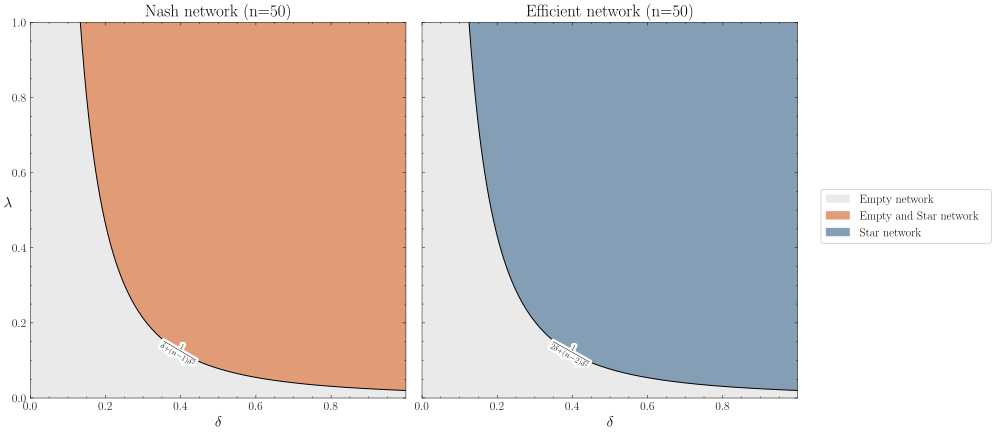

In [4]:
fig, axes = plt.subplots(
    1, 2, figsize=(12, 6), sharex=True, sharey=True, layout="compressed"
)

# -------------------------
# Left panel: Nash network
# -------------------------

nash_y1, nash_label1 = nash_f1(x, n)
nash_y2, nash_label2 = nash_f2(x, n)
nash_y3, nash_label3 = nash_f3(x, n)

N1 = nash_y1[None, :]
N2 = nash_y2[None, :]
N3 = nash_y3[None, :]

# 0 = Empty, 1 = Empty+Star, 2 = Star, 3 = Complete
Z_nash = np.zeros_like(Y, dtype=int)
Z_nash[Y > N3] = 1
Z_nash[Y > N2] = 2
Z_nash[Y > N1] = 3

ax = axes[0]

nash_region_colors = [
    REGION_COLORS["empty"],
    REGION_COLORS["empty_and_star"],
    REGION_COLORS["star"],
    REGION_COLORS["complete"],
]
nash_region_labels = [
    "Empty network",
    "Empty and Star network",
    "Star network",
    "Complete network",
]

ax.contourf(
    X,
    Y,
    Z_nash,
    levels=[-0.5, 0.5, 1.5, 2.5, 3.5],
    colors=nash_region_colors,
    alpha=0.55,
)

(line1,) = ax.plot(x, nash_y1, color="black", label=nash_label1)
(line2,) = ax.plot(x, nash_y2, color="black", label=nash_label2)
(line3,) = ax.plot(x, nash_y3, color="black", label=nash_label3)

labelLines(
    [line1, line2, line3],
    xvals=[0.4, 0.4, 0.4],
    fontsize=plt.rcParams["legend.fontsize"],
)

#ax.plot(0.9, 10 / (2 * n), "x", color="black", markersize=12)
ax.set_title(f"Nash network (n={n})")
ax.set_xlabel(r"$\delta$")
ax.set_ylabel(r"$\lambda$", rotation=0)
ax.set_box_aspect(1)

# -------------------------
# Right panel: Efficient network
# -------------------------

eff_y1, eff_label1 = eff_f1(x, n)
eff_y2, eff_label2 = eff_f2(x, n)

E1 = eff_y1[None, :]
E2 = eff_y2[None, :]

# 0 = Empty, 1 = Star, 2 = Complete
Z_eff = np.zeros_like(Y, dtype=int)
Z_eff[Y > E2] = 1
Z_eff[Y > E1] = 2

ax = axes[1]

eff_region_colors = [
    REGION_COLORS["empty"],
    REGION_COLORS["star"],
    REGION_COLORS["complete"],
]
eff_region_labels = ["Empty network", "Star network", "Complete network"]

ax.contourf(
    X, Y, Z_eff, levels=[-0.5, 0.5, 1.5, 2.5], colors=eff_region_colors, alpha=0.55
)

(line4,) = ax.plot(x, eff_y1, color="black", label=eff_label1)
(line5,) = ax.plot(x, eff_y2, color="black", label=eff_label2)

labelLines(
    [line4, line5],
    xvals=[0.4, 0.4],
    fontsize=plt.rcParams["legend.fontsize"],
)

#ax.plot(0.9, 10 / (2 * n), "x", color="black", markersize=12)
ax.set_title(f"Efficient network (n={n})")
ax.set_xlabel(r"$\delta$")
ax.set_box_aspect(1)

# Common axis limits
for ax in axes:
    ax.set_xlim(0, x.max())
    ax.set_ylim(0, y.max())

# -------------------------
# Combined legend outside right
# -------------------------

region_handles = [
    Patch(
        facecolor=REGION_COLORS["empty"],
        edgecolor="none",
        alpha=0.55,
        label="Empty network",
    ),
    Patch(
        facecolor=REGION_COLORS["empty_and_star"],
        edgecolor="none",
        alpha=0.55,
        label="Empty and Star network",
    ),
    Patch(
        facecolor=REGION_COLORS["star"],
        edgecolor="none",
        alpha=0.55,
        label="Star network",
    ),
]

fig.legend(
    handles=region_handles,
    loc="center left",
    bbox_to_anchor=(0.980, 0.5),
    frameon=True,
)
plt.show()